# INF672 · Machine Learning — Unidad 2
## Práctica 1: estadística, vectores, probabilidad, preprocesamiento y gradiente

**Estudiante:** Ramiro
**Curso:** INF672 · Ingeniería Informática · UATF

Este notebook resuelve los diez ejercicios de la Práctica 1. Cada ejercicio incluye el código
ejecutado y una celda de texto con las respuestas del apartado *Para entregar*.

In [1]:
# Configuración inicial (se usa en todo el notebook)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
import itertools

rng = np.random.default_rng(42)   # generador de números aleatorios, semilla fija para reproducibilidad
sns.set_theme(style="whitegrid")

## Ejercicio 01 — ¿Cuánto sale par? Estima una probabilidad tirando el dado

**Idea:** en vez de usar la probabilidad teórica (3/6 = 0.5), la estimamos tirando el dado
muchas veces y contando qué fracción de tiradas dio un número par. Esto es el **enfoque
frecuentista**: probabilidad = frecuencia relativa de un evento cuando el número de intentos
crece.

In [2]:
resultados_ej1 = {}

for N in [100, 1000, 100_000]:
    tiradas = rng.integers(1, 7, size=N)          # N tiradas de un dado (1 a 6)
    pares = (tiradas % 2 == 0).sum()              # cuenta cuántas salieron pares
    prob_estimada = pares / N                     # frecuencia relativa
    error = abs(prob_estimada - 0.5)
    resultados_ej1[N] = (pares, prob_estimada, error)
    print(f"N={N:>7} | pares={pares:>7} | P(par) estimada = {prob_estimada:.4f} | "
          f"error frente a 0.5 = {error:.4f}")

N=    100 | pares=     38 | P(par) estimada = 0.3800 | error frente a 0.5 = 0.1200
N=   1000 | pares=    489 | P(par) estimada = 0.4890 | error frente a 0.5 = 0.0110
N= 100000 | pares=  49979 | P(par) estimada = 0.4998 | error frente a 0.5 = 0.0002


**respuesta:**

| N | pares | P(par) estimada | error vs. 0.5 |
|---|---|---|---|
| 100 | 38 | 0.3800 | 0.1200 |
| 1 000 | 489 | 0.4890 | 0.0110 |
| 100 000 | 49979 | 0.4998 | 0.0002 |

Con N = 100 000 la estimación fue la que más se acercó a 0.5, porque al aumentar el número de
lanzamientos las fluctuaciones aleatorias se compensan entre sí: el
promedio de muchos ensayos converge al valor teórico. Con pocos datos (N = 100) la estimación es
más ruidosa e inestable — puede alejarse bastante de 0.5 solo por azar. Con más datos ese margen de
error se reduce.

## Ejercicio 02 — Radiografía de una característica

**Idea:** describir con cinco números una sola variable (sin cruzarla con otras): tendencia
central (media, mediana), dispersión (desviación estándar) y rango (mínimo, máximo).

In [3]:
iris = load_iris(as_frame=True)
df_iris = iris.frame.copy()
df_iris["species"] = df_iris["target"].map(dict(enumerate(iris.target_names)))

petal_length = df_iris["petal length (cm)"].values

media   = np.mean(petal_length)
mediana = np.median(petal_length)
desv    = np.std(petal_length)
minimo  = np.min(petal_length)
maximo  = np.max(petal_length)

print(f"Media:              {media:.3f} cm")
print(f"Mediana:            {mediana:.3f} cm")
print(f"Desviación estándar:{desv:.3f} cm")
print(f"Mínimo:             {minimo:.3f} cm")
print(f"Máximo:             {maximo:.3f} cm")

Media:              3.758 cm
Mediana:            4.350 cm
Desviación estándar:1.759 cm
Mínimo:             1.000 cm
Máximo:             6.900 cm


**respuesta:**

- **Media (≈3.76 cm):** el largo de pétalo "promedio" si repartiéramos el total entre todas las flores.
- **Mediana (≈4.35 cm):** el valor que deja la mitad de las flores por debajo y la mitad por
  encima; que sea más alta que la media sugiere que hay más flores con pétalos cortos "jalando"
  el promedio hacia abajo (asimetría hacia la izquierda en la cola baja).
- **Desviación estándar (≈1.76 cm):** qué tan dispersos están los valores respecto a la media. Es
  grande en relación a la media (casi el 47% de ella), lo que indica que el largo de pétalo varía
  mucho de una flor a otra — no es una característica homogénea en todo el dataset.
- **Mínimo (1.0 cm):** el pétalo más corto observado.
- **Máximo (6.9 cm):** el pétalo más largo observado, casi 7 veces el mínimo.

La media y la mediana están relativamente alejadas (3.76 vs 4.35), lo que sugiere que la
distribución **no es simétrica**: probablemente es bimodal o tiene cola hacia los valores bajos,
algo consistente con que Iris mezcla tres especies con pétalos de tamaños bien distintos.

## Ejercicio 03 — ¿Qué tan lejos están dos flores?

**Idea:** cada flor es un vector de 4 números. La distancia euclidiana mide qué tan "lejos" están
dos vectores — flores parecidas (misma especie) deberían tener una distancia menor que flores de
especies distintas.

In [4]:
# Elegimos 3 flores: dos de la misma especie (setosa) y una de otra (virginica)
idx_a, idx_b, idx_c = 0, 1, 120   # 0 y 1 son setosa; 120 es virginica
print(df_iris.loc[[idx_a, idx_b, idx_c], ["sepal length (cm)", "sepal width (cm)",
                                           "petal length (cm)", "petal width (cm)", "species"]])

cols = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]
a = df_iris.loc[idx_a, cols].values.astype(float)
b = df_iris.loc[idx_b, cols].values.astype(float)
c = df_iris.loc[idx_c, cols].values.astype(float)

def dist_a_mano(v1, v2):
    return np.sqrt(np.sum((v1 - v2) ** 2))

def dist_numpy(v1, v2):
    return np.linalg.norm(v1 - v2)

d_ab_mano, d_ab_np = dist_a_mano(a, b), dist_numpy(a, b)
d_ac_mano, d_ac_np = dist_a_mano(a, c), dist_numpy(a, c)

print(f"\nDistancia setosa-setosa   (a-b): a mano = {d_ab_mano:.4f} | numpy = {d_ab_np:.4f}")
print(f"Distancia setosa-virginica (a-c): a mano = {d_ac_mano:.4f} | numpy = {d_ac_np:.4f}")

     sepal length (cm)  sepal width (cm)  ...  petal width (cm)    species
0                  5.1               3.5  ...               0.2     setosa
1                  4.9               3.0  ...               0.2     setosa
120                6.9               3.2  ...               2.3  virginica

[3 rows x 5 columns]

Distancia setosa-setosa   (a-b): a mano = 0.5385 | numpy = 0.5385
Distancia setosa-virginica (a-c): a mano = 5.1215 | numpy = 5.1215


**respuesta:**

Los dos métodos (a mano y `np.linalg.norm`) dan exactamente el mismo resultado en ambos pares,
como debía ser, porque `np.linalg.norm` calcula internamente lo mismo que la fórmula manual.

La distancia entre las dos flores **setosa** resultó mucho **menor** que la distancia hacia la
flor **virginica**. Tiene sentido: flores de la misma especie comparten un rango típico de
medidas (largo/ancho de sépalo y pétalo), así que sus vectores de características caen cerca uno
del otro en el espacio de 4 dimensiones. Flores de especies distintas tienden a tener medidas
distintas (por ejemplo, virginica tiene pétalos notablemente más largos que setosa), lo que las
aleja en ese mismo espacio. Esta es justamente la idea detrás de algoritmos como k-NN: "cercanía
numérica" funciona como aproximación de "pertenece a la misma clase".

## Ejercicio 04 — Limpiar una tabla, paso a paso

**Idea:** practicar los tres gestos básicos de preprocesamiento por separado: detectar
faltantes, imputarlos, y codificar texto como números.

In [5]:
df_ej4 = pd.DataFrame({
    "ingreso": [3200, 4100, np.nan, 2800, 5000, np.nan, 3600, 4800],
    "ciudad":  ["Potosí", "Sucre", "Potosí", "La Paz", np.nan, "Sucre", "Potosí", "La Paz"],
    "edad":    [28, 35, 41, 23, 52, 30, 45, 38],
})

print("Tabla original:")
print(df_ej4)

print("\n1) Faltantes por columna:")
print(df_ej4.isna().sum())

Tabla original:
   ingreso  ciudad  edad
0   3200.0  Potosí    28
1   4100.0   Sucre    35
2      NaN  Potosí    41
3   2800.0  La Paz    23
4   5000.0     NaN    52
5      NaN   Sucre    30
6   3600.0  Potosí    45
7   4800.0  La Paz    38

1) Faltantes por columna:
ingreso    2
ciudad     1
edad       0
dtype: int64


In [6]:
# 2) Imputar 'ingreso' con la mediana
mediana_ingreso = df_ej4["ingreso"].median()
df_ej4["ingreso"] = df_ej4["ingreso"].fillna(mediana_ingreso)
print(f"Mediana usada para imputar 'ingreso': {mediana_ingreso}")

# 3) Codificar 'ciudad' con one-hot encoding
df_ej4_final = pd.get_dummies(df_ej4, columns=["ciudad"])
print("\nTabla final (sin faltantes y sin texto):")
print(df_ej4_final)

Mediana usada para imputar 'ingreso': 3850.0

Tabla final (sin faltantes y sin texto):
   ingreso  edad  ciudad_La Paz  ciudad_Potosí  ciudad_Sucre
0   3200.0    28          False           True         False
1   4100.0    35          False          False          True
2   3850.0    41          False           True         False
3   2800.0    23           True          False         False
4   5000.0    52          False          False         False
5   3850.0    30          False          False          True
6   3600.0    45          False           True         False
7   4800.0    38           True          False         False


**respuesta:**

La columna con más valores faltantes es **ingreso**, con 2 faltantes; **ciudad** tiene 1 faltante
y **edad** no tiene ninguno (ver `isna().sum()` en la celda anterior).

**¿Por qué la mediana y no la media para imputar ingreso?** El ingreso es una variable propensa a
tener valores extremos (unos pocos ingresos muy altos pueden aparecer en cualquier muestra). La
media es sensible a esos extremos — un solo valor muy alto la "arrastra" hacia arriba y ya no
representa bien al ingreso típico. La mediana, en cambio, solo depende del valor central de los
datos ordenados y no se ve afectada por outliers, así que imputar con la mediana produce un valor
más representativo y no distorsiona la distribución real de la columna.

**¿Qué representa cada columna nueva de `get_dummies`?** Cada categoría de `ciudad` se convierte
en su propia columna binaria (`ciudad_La Paz`, `ciudad_Potosí`, `ciudad_Sucre`, ...): un 1 indica
que esa fila pertenece a esa ciudad y un 0 que no. Esto es necesario porque los modelos de
machine learning trabajan con números, no con texto, así que el texto categórico se traduce a un
conjunto de columnas 0/1 que el modelo sí puede procesar (codificación one-hot).

## Ejercicio 05 — ¿Se mueven juntas dos variables?

**Idea:** ver primero "con los ojos" (histograma, dispersión) si dos variables están
relacionadas, y luego confirmarlo con un número: el coeficiente de correlación de Pearson.

Coeficiente de correlación de Pearson: 0.9629


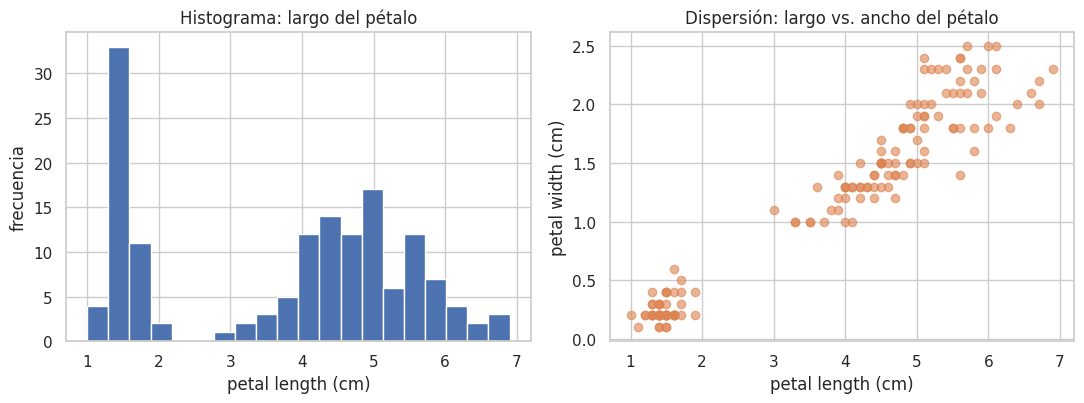

In [7]:
largo = df_iris["petal length (cm)"].values
ancho = df_iris["petal width (cm)"].values

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].hist(largo, bins=20, color="#4C72B0", edgecolor="white")
axes[0].set_title("Histograma: largo del pétalo")
axes[0].set_xlabel("petal length (cm)")
axes[0].set_ylabel("frecuencia")

axes[1].scatter(largo, ancho, alpha=0.6, color="#DD8452")
axes[1].set_title("Dispersión: largo vs. ancho del pétalo")
axes[1].set_xlabel("petal length (cm)")
axes[1].set_ylabel("petal width (cm)")

plt.tight_layout()
plt.show()

correlacion = np.corrcoef(largo, ancho)[0, 1]
print(f"Coeficiente de correlación de Pearson: {correlacion:.4f}")

**respuesta:**

El número (r ≈ 0.96) coincide totalmente con lo que muestra la nube de puntos: los puntos suben
casi en línea recta, sin apenas dispersión alrededor de la tendencia — una relación lineal muy
fuerte.

**Interpretación de Pearson:**
- Un valor cercano a **+1** indica una relación lineal positiva casi perfecta (cuando una
  variable sube, la otra sube proporcionalmente).
- Un valor cercano a **0** indica que no hay relación lineal apreciable entre las variables.
- Un valor cercano a **−1** indica una relación lineal negativa casi perfecta (cuando una sube,
  la otra baja proporcionalmente).

Aquí, el valor tan cercano a +1 confirma que el largo y el ancho del pétalo crecen prácticamente
juntos: son dos formas distintas de medir "qué tan grande es el pétalo", por lo que tiene sentido
que estén tan correlacionadas.

## Ejercicio 06 — Perfil estadístico por especie

**Idea:** en vez de mirar cada característica sola (Ejercicio 2) o el dataset completo, ahora
comparamos las tres especies entre sí para ver cuál característica las distingue mejor.

In [8]:
def rango(x):
    return x.max() - x.min()

agg_funcs = ["mean", "median", "std", rango,
             lambda x: x.quantile(0.25),
             lambda x: x.quantile(0.50),
             lambda x: x.quantile(0.75)]
nombres = ["media", "mediana", "std", "rango", "Q1", "Q2", "Q3"]

caracteristicas = ["sepal length (cm)", "sepal width (cm)",
                   "petal length (cm)", "petal width (cm)"]

perfil = df_iris.groupby("species")[caracteristicas].agg(agg_funcs)
perfil.columns = pd.MultiIndex.from_product([caracteristicas, nombres])
perfil = perfil.round(3)
perfil

sepal length (cm)                       ... petal width (cm)               
                       media mediana    std rango  ...            rango   Q1   Q2   Q3
species                                            ...                                
setosa                 5.006     5.0  0.352   1.5  ...              0.5  0.2  0.2  0.3
versicolor             5.936     5.9  0.516   2.1  ...              0.8  1.2  1.3  1.5
virginica              6.588     6.5  0.636   3.0  ...              1.1  1.8  2.0  2.3

[3 rows x 28 columns]

**respuesta:**

La característica que **mejor separa** a las tres especies es **petal length (cm)** (largo del
pétalo), y en segundo lugar **petal width (cm)**. Se puede leer directamente en la tabla: sus
medias son muy distintas entre especies (setosa muy baja, versicolor intermedia, virginica alta)
mientras que la desviación estándar **dentro** de cada especie es relativamente pequeña. Esa
combinación — medias muy separadas + poca dispersión interna — es justamente la que produce
grupos bien diferenciados: los rangos de valores de cada especie casi no se solapan entre sí.
En cambio, `sepal width (cm)` tiene medias mucho más parecidas entre especies y por eso separa
peor.

## Ejercicio 07 — Tres formas de comparar dos flores, hechas por ti

**Idea:** implementar desde cero, solo con NumPy, las tres operaciones más comunes para comparar
vectores: distancia euclidiana, producto punto y similitud coseno.

In [9]:
def distancia_euclidiana(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

def producto_punto(a, b):
    return np.sum(a * b)

def similitud_coseno(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# 4 flores: dos de la misma especie (setosa) y dos de especies distintas (versicolor, virginica)
indices = {"setosa_1": 0, "setosa_2": 5, "versicolor": 60, "virginica": 110}
vectores = {nombre: df_iris.loc[idx, cols].values.astype(float)
            for nombre, idx in indices.items()}

pares = list(itertools.combinations(vectores.keys(), 2))
filas = []
for n1, n2 in pares:
    v1, v2 = vectores[n1], vectores[n2]
    filas.append({
        "par": f"{n1} - {n2}",
        "distancia_euclidiana": round(distancia_euclidiana(v1, v2), 4),
        "producto_punto": round(producto_punto(v1, v2), 4),
        "similitud_coseno": round(similitud_coseno(v1, v2), 4),
    })

tabla_ej7 = pd.DataFrame(filas)
tabla_ej7

,par,distancia_euclidiana,producto_punto,similitud_coseno
0,setosa_1 - setosa_2,0.6164,43.65,0.9990
1,setosa_1 - versicolor,2.7037,37.60,0.9117
2,setosa_1 - virginica,4.3566,51.89,0.9004
3,setosa_2 - versicolor,2.7148,41.15,0.9193
4,setosa_2 - virginica,3.9774,57.05,0.9121
5,versicolor - virginica,2.6926,58.75,0.9951


**respuesta:**

En general, la similitud coseno y la distancia euclidiana **coinciden** en identificar el par
`setosa_1 - setosa_2` como el más parecido (mayor similitud coseno y menor distancia euclidiana),
y los pares entre especies distintas como los más disímiles. Esto es esperable porque ambas
métricas capturan, de formas distintas, la misma idea de "cercanía" entre vectores con
magnitudes parecidas.

Pueden **discrepar** cuando dos vectores apuntan "en la misma dirección" pero tienen magnitudes
muy distintas: la similitud coseno solo mira el **ángulo** entre los vectores (ignora qué tan
largos son), mientras que la distancia euclidiana sí depende de la **magnitud** — dos flores con
proporciones parecidas entre sus 4 medidas pero de tamaño global distinto (una "flor grande" y
una "flor chica" con la misma forma relativa) tendrían coseno alto (ángulo pequeño) pero
distancia euclidiana considerable. En Iris esto es menos común porque todas las medidas están en
rangos similares, pero es la explicación conceptual de por qué las dos métricas no siempre
concuerdan.

## Ejercicio 08 — Leer los datos con la vista

**Idea:** producir tres vistas visuales clásicas de Iris y, sobre todo, interpretarlas: ¿qué
características separan bien a las especies y cuáles se confunden?

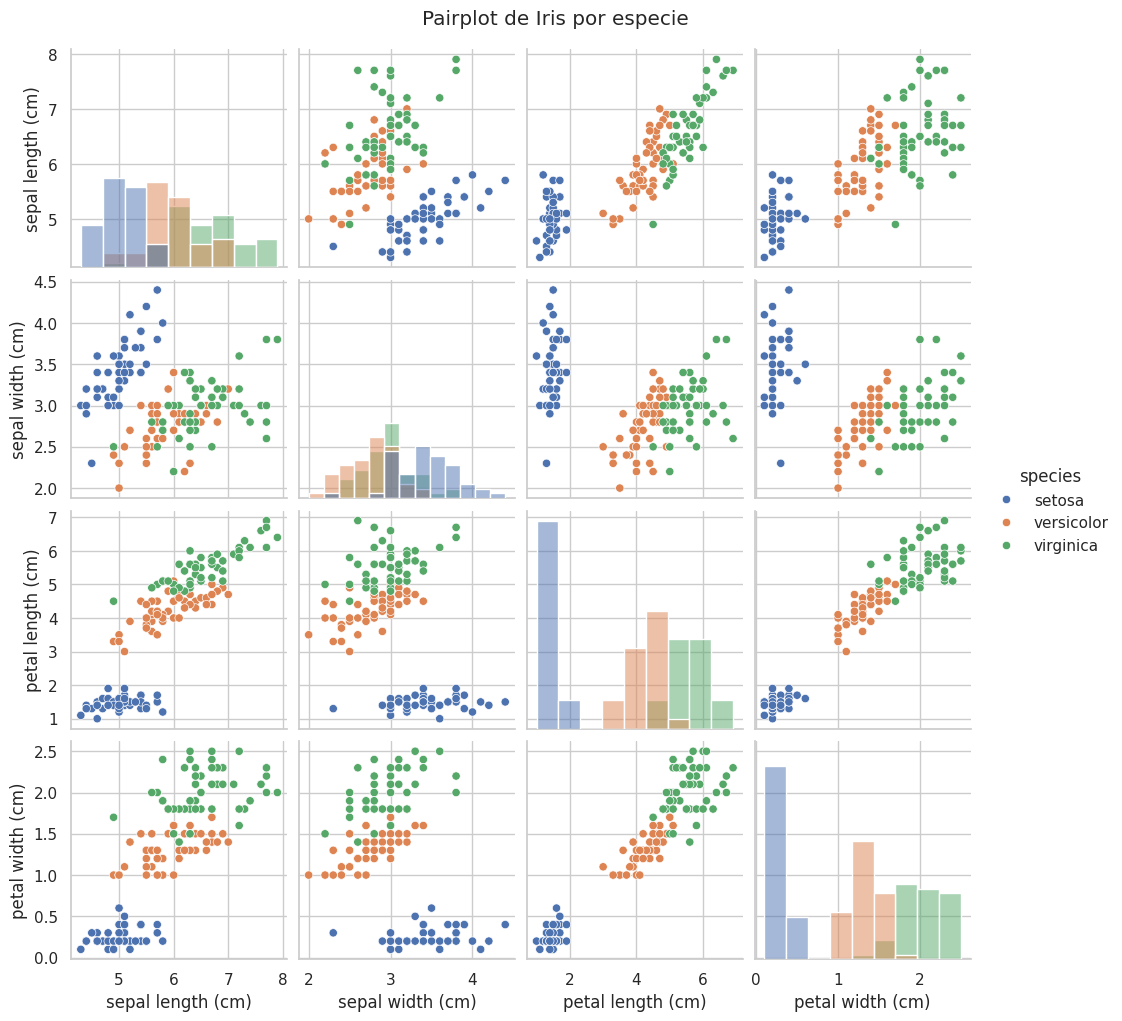

In [10]:
pairplot_fig = sns.pairplot(df_iris.drop(columns=["target"]), hue="species", diag_kind="hist")
pairplot_fig.fig.suptitle("Pairplot de Iris por especie", y=1.02)
plt.show()

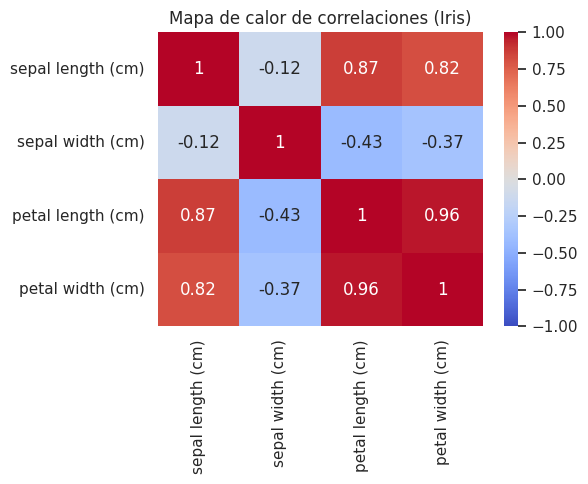

In [11]:
plt.figure(figsize=(6, 5))
sns.heatmap(df_iris[caracteristicas].corr(numeric_only=True), annot=True, cmap="coolwarm",
            vmin=-1, vmax=1)
plt.title("Mapa de calor de correlaciones (Iris)")
plt.tight_layout()
plt.show()

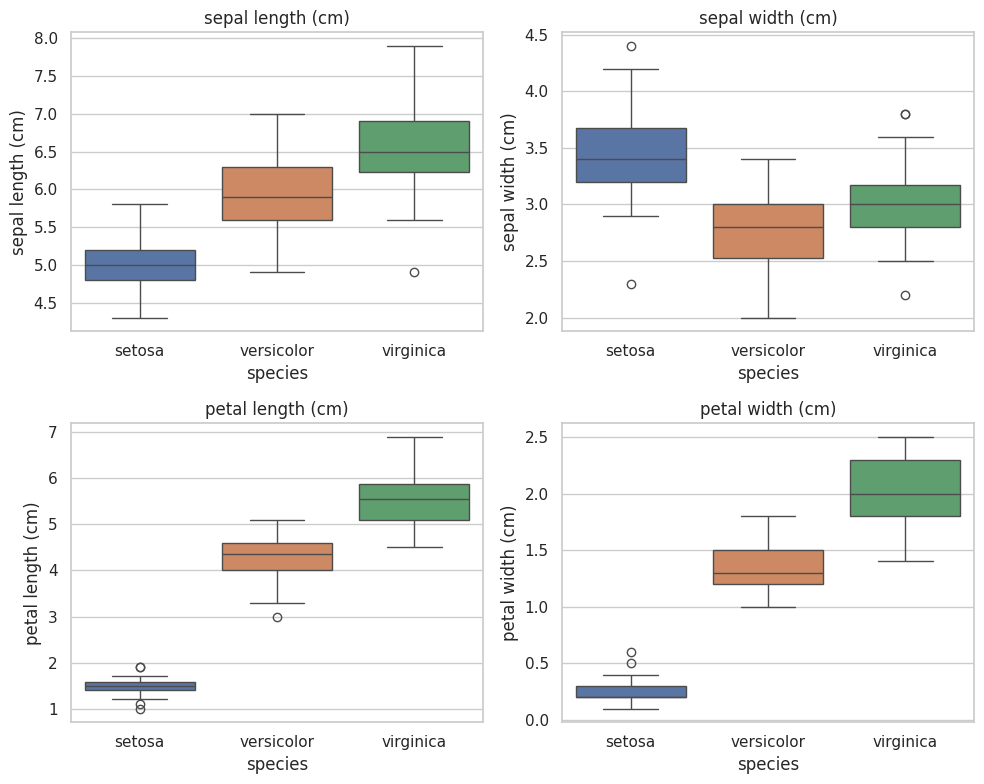

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, carac in zip(axes.ravel(), caracteristicas):
    sns.boxplot(data=df_iris, x="species", y=carac, ax=ax, hue="species", legend=False)
    ax.set_title(carac)
plt.tight_layout()
plt.show()

**respuesta:**

En el **pairplot** y en los **boxplots** se ve claramente que `petal length` y `petal width` son
el par que **mejor separa** a las tres especies: en el scatter de esas dos variables, las tres
especies forman nubes de puntos casi sin solaparse, y en sus boxplots las cajas de cada especie
están en rangos bien distintos con poco o ningún traslape (sobre todo setosa, que queda
totalmente aislada de las otras dos).

En cambio, `sepal width` es la característica que más **confunde**: en su boxplot las tres
especies tienen cajas muy superpuestas, y en el pairplot cualquier combinación que incluya
`sepal width` muestra las nubes de puntos mezcladas, sin una separación clara.

El **mapa de calor** confirma esto de forma numérica: `petal length` y `petal width` tienen una
correlación muy alta entre sí (≈0.96, como en el Ejercicio 5) y ambas están fuertemente
correlacionadas con la especie de forma indirecta (a través de sus medias tan distintas por
grupo), mientras que `sepal width` tiene correlaciones bajas con el resto de variables.

## Ejercicio 09 — Bajar la colina: descenso de gradiente a mano

**Idea:** implementar el mecanismo de descenso de gradiente sobre una función muy simple,
`f(x) = (x-3)² + 2`, cuyo mínimo (x = 3) ya conocemos de antemano, para ver con claridad cómo
la tasa de aprendizaje afecta la convergencia.

In [13]:
def f(x):
    return (x - 3) ** 2 + 2

def derivada_numerica(x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

def descenso_gradiente(x_inicial, tasa, pasos=30):
    x = x_inicial
    trayectoria = [x]
    for _ in range(pasos):
        x = x - tasa * derivada_numerica(x)
        trayectoria.append(x)
    return trayectoria

tasas = {"pequeña (0.01)": 0.01, "intermedia (0.1)": 0.1, "grande (1.1)": 1.1}
trayectorias = {nombre: descenso_gradiente(10.0, tasa) for nombre, tasa in tasas.items()}

for nombre, trayectoria in trayectorias.items():
    print(f"Tasa {nombre}: x final = {trayectoria[-1]:.4f} (tras {len(trayectoria)-1} pasos)")

Tasa pequeña (0.01): x final = 6.8184 (tras 30 pasos)
Tasa intermedia (0.1): x final = 3.0087 (tras 30 pasos)
Tasa grande (1.1): x final = 1664.6341 (tras 30 pasos)


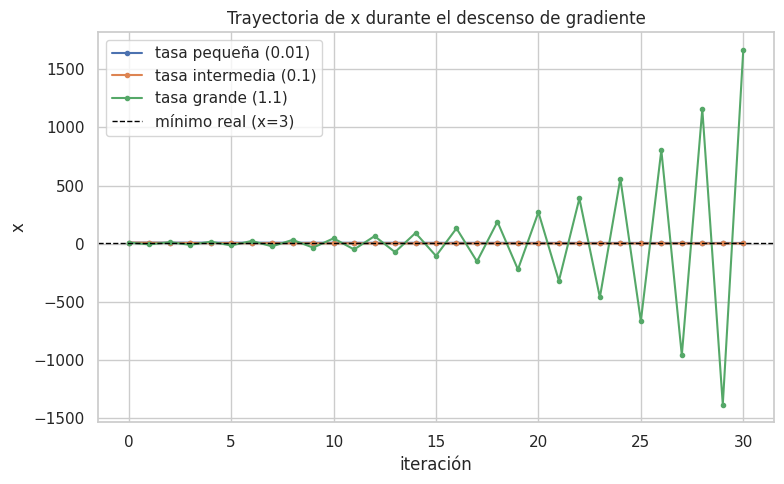

In [14]:
plt.figure(figsize=(8, 5))
for nombre, trayectoria in trayectorias.items():
    plt.plot(trayectoria, marker="o", markersize=3, label=f"tasa {nombre}")
plt.axhline(3, color="black", linestyle="--", linewidth=1, label="mínimo real (x=3)")
plt.xlabel("iteración")
plt.ylabel("x")
plt.title("Trayectoria de x durante el descenso de gradiente")
plt.legend()
plt.tight_layout()
plt.show()

**respuesta:**

No todas llegan cerca de x = 3. Con tasa **pequeña (0.01)** el descenso avanza correctamente
hacia el mínimo, pero muy **lento**: en 30 pasos todavía no alcanza a acercarse del todo (se
necesitarían muchas más iteraciones). Con tasa **intermedia (0.1)** converge de forma rápida y
estable a x ≈ 3 en pocos pasos — es el mejor comportamiento de las tres. Con tasa **grande
(1.1)**, cada paso "se pasa" del mínimo hacia el lado contrario y la magnitud del salto no se
reduce con el tiempo: x **oscila** y, como 1.1 está por encima del límite de estabilidad para
esta parábola, en vez de acercarse la distancia al mínimo **crece** en cada iteración (diverge).

Esto ilustra por qué la elección de la tasa de aprendizaje es delicada: si es muy chica el
entrenamiento es innecesariamente lento (se gastan muchas iteraciones sin necesidad); si es
demasiado grande, el algoritmo puede volverse inestable y nunca converger, incluso alejándose más
del óptimo en cada paso.

## Ejercicio 10 — Contar y simular: dos caminos hacia una probabilidad

**Evento elegido:** "al menos un 6 al tirar cuatro dados".

**Idea:** calcular la misma probabilidad de dos formas independientes —enumerando todo el
espacio muestral (exacto) y simulando muchas tiradas (estimado)— y comprobar que convergen al
mismo valor.

In [15]:
# 1) Valor exacto por conteo (enumeración completa del espacio muestral)
espacio_muestral = list(itertools.product(range(1, 7), repeat=4))   # 6^4 = 1296 resultados posibles
favorables = [r for r in espacio_muestral if 6 in r]
valor_exacto = len(favorables) / len(espacio_muestral)

print(f"Tamaño del espacio muestral: {len(espacio_muestral)}")
print(f"Casos favorables (al menos un 6): {len(favorables)}")
print(f"Valor exacto (por conteo): {valor_exacto:.6f}")

Tamaño del espacio muestral: 1296
Casos favorables (al menos un 6): 671
Valor exacto (por conteo): 0.517747


In [16]:
# 2) Estimación por simulación para distintos tamaños de muestra
tamanos_N = [10, 100, 10_000, 100_000]
estimaciones = []
errores = []

for N in tamanos_N:
    tiradas = rng.integers(1, 7, size=(N, 4))          # N tiradas de 4 dados cada una
    evento = (tiradas == 6).any(axis=1)                # True si al menos un dado salió 6
    estimacion = evento.mean()                          # frecuencia relativa
    estimaciones.append(estimacion)
    errores.append(abs(estimacion - valor_exacto))

tabla_error = pd.DataFrame({
    "N": tamanos_N,
    "estimación": estimaciones,
    "valor_exacto": valor_exacto,
    "error_absoluto": errores,
})
tabla_error

,N,estimación,valor_exacto,error_absoluto
0,10,0.20000,0.517747,0.317747
1,100,0.50000,0.517747,0.017747
2,10000,0.51640,0.517747,0.001347
3,100000,0.51599,0.517747,0.001757


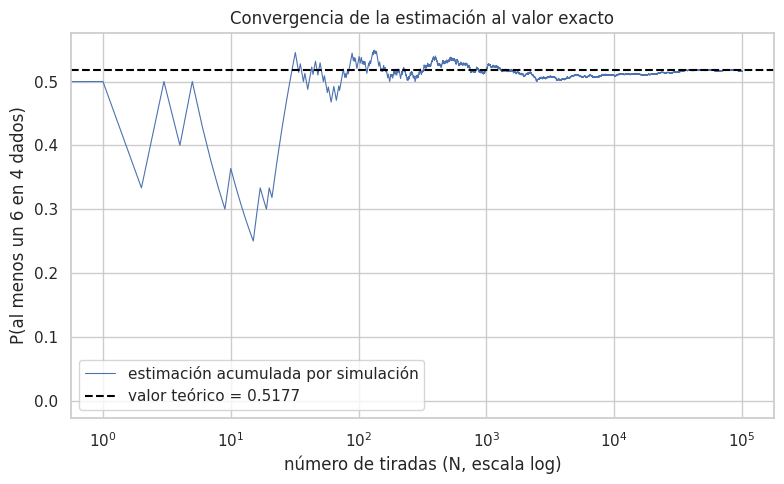

In [17]:
# 3) Gráfico de convergencia (usando una sola secuencia larga de tiradas acumuladas)
N_max = 100_000
tiradas_largas = rng.integers(1, 7, size=(N_max, 4))
evento_largo = (tiradas_largas == 6).any(axis=1)
estimacion_acumulada = np.cumsum(evento_largo) / np.arange(1, N_max + 1)

plt.figure(figsize=(8, 5))
plt.plot(estimacion_acumulada, color="#4C72B0", linewidth=0.8,
         label="estimación acumulada por simulación")
plt.axhline(valor_exacto, color="black", linestyle="--", label=f"valor teórico = {valor_exacto:.4f}")
plt.xscale("log")
plt.xlabel("número de tiradas (N, escala log)")
plt.ylabel("P(al menos un 6 en 4 dados)")
plt.title("Convergencia de la estimación al valor exacto")
plt.legend()
plt.tight_layout()
plt.show()

**respuesta:**

El valor exacto por conteo es **P(al menos un 6 en 4 dados) = 671/1296 ≈ 0.5177**.

En la tabla de errores (ver arriba) se observa que el error absoluto entre la estimación y el
valor exacto disminuye conforme N crece — con N = 10 el error puede ser grande (incluso de varias
décimas, dependiendo de la tirada), y ya con N = 10 000 o N = 100 000 el error suele estar por
debajo de 0.01. En la práctica, la estimación empieza a volverse confiable (error consistentemente
pequeño, digamos por debajo de 0.01–0.02) a partir de N en el orden de varios miles.

La relación entre el número de tiradas y el error no es lineal: el error de una estimación por
simulación decrece aproximadamente como 1/√N (una propiedad general de la estimación de
probabilidades por muestreo). Esto significa que para reducir el error a la mitad hace falta
**cuadruplicar** N, no solo duplicarlo — por eso pasar de 10 a 100 mejora mucho la estimación,
pero pasar de 10 000 a 100 000 la mejora proporcionalmente menos, aunque siga acercándola al
valor teórico.

## Conclusión

Este cuaderno cubrió, con ejemplos concretos, las cinco piezas matemáticas y de datos que
sostienen los modelos de la Unidad 2: estimar probabilidades por frecuencia (Ej. 1 y 10),
describir variables con estadística descriptiva (Ej. 2 y 6), medir similitud entre vectores
(Ej. 3 y 7), preprocesar datos crudos (Ej. 4) y explorar relaciones entre variables de forma
visual y numérica (Ej. 5 y 8), además del mecanismo de optimización — descenso de gradiente
(Ej. 9) — que usan los propios modelos para aprender.